# Co-add the visits of each band and night

Surveys often observe the same field several times in a night: LSST deep drilling fields, for instance, take
sequences of visits in each band. A transient seen at 4 sigma in each of 10 visits of a night is not detected in any
of them individually, but their co-addition is a $4\sqrt{10} = 12.6\,\sigma$ detection.

{meth}`skysurvey.DataSet.get_data` and {meth}`skysurvey.DataSet.get_ndetection` can join the observations of each
target taken in the same band and the same night (`join_bandday=True`), or over several nights
(e.g. `join_bandday=3`). By default (`join_how="coadd"`), they are
**co-added**: the inverse-variance weighted mean of the fluxes, with error $1/\sqrt{\sum_i 1/\sigma_i^2}$.

This guide uses one year of SNe Ia in the LSST COSMOS deep drilling field.

:::{note}
This needs the OpSim database `baseline_v5.1.0_10yrs.db` (see {doc}`../quickstart/lsst_deepfield`).
:::

In [1]:
import numpy as np
import pandas
import matplotlib.pyplot as plt
import shapely

import skysurvey
from skysurvey.target.snia import frohmaier_rate

OPSIM_FILEPATH = "baseline_v5.1.0_10yrs.db" # replace with the path to your OpSim file

## Simulate the SNe Ia of a deep field

We load the visits of the COSMOS deep drilling sequences during the first year of LSST, draw the SNe Ia exploding
in the observed area, and simulate their lightcurves. We also simulate them **without noise** (`incl_error=False`):
the truth, to check the co-addition.

In [2]:
survey = skysurvey.LSST.from_opsim(OPSIM_FILEPATH, sql_where="night < 365 AND observation_reason = 'ddf_cosmos'")
tstart, tstop = survey.get_timerange()
snia = skysurvey.SNeIa.from_draw(rate=frohmaier_rate, tstart=tstart - 50, tstop=tstop + 20, zmax=1.0,
                                 skyarea=shapely.union_all(survey.get_skyarea()))

dset = skysurvey.DataSet.from_targets_and_survey(snia, survey, seed=1234)
truth = skysurvey.DataSet.from_targets_and_survey(snia, survey, incl_error=False) # same visits, no noise
print(f"{len(survey.data):,} visits, {len(snia.data):,} SNe Ia, {len(dset.data):,} observations")

559 visits, 1,557 SNe Ia, 296,661 observations


## What is a night?

Observations are grouped per night, and a night must not be split at 0h UT: in Chile, 0h UT falls in the middle of
the night. The night boundary comes from the survey logs themselves
({meth}`~skysurvey.survey.core.BaseSurvey.get_night_boundary`): folding all the observation times on one day, an
observatory never observes during its daytime, and the middle of this empty interval separates two nights. This
works for any ground-based survey; with observations at all times of day (space telescope), give the observatory
`longitude` instead.

night boundary from the logs: 15.00 h UT (Rubin local noon: 16.72 h UT)


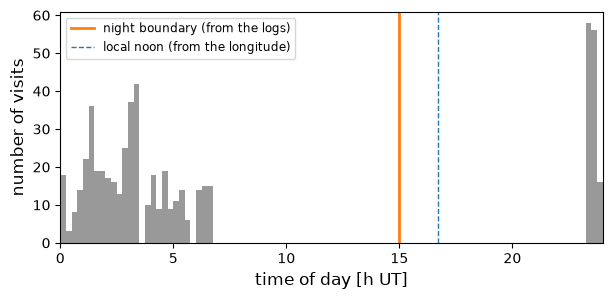

In [3]:
boundary = survey.get_night_boundary()
local_noon = survey.get_night_boundary(longitude=-70.75) # Rubin, from its longitude
print(f"night boundary from the logs: {boundary * 24:.2f} h UT (Rubin local noon: {local_noon * 24:.2f} h UT)")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(survey.data["mjd"] % 1 * 24, bins=np.arange(0, 24.25, 0.25), color="0.6")
ax.axvline(boundary * 24, color="C1", lw=2, label="night boundary (from the logs)")
ax.axvline(local_noon * 24, color="C0", lw=1, ls="--", label="local noon (from the longitude)")
ax.set_xlabel("time of day [h UT]", fontsize="large")
ax.set_ylabel("number of visits", fontsize="large")
ax.set_xlim(0, 24)
ax.legend(fontsize="small");

With few logs (here one field during one year), the boundary is not exactly at local noon, but it is hours away
from any observation, which is all that matters to group the visits per night.

## Co-add the observations of each band and night

`get_data(join_bandday=True)` returns one row per (target, band, night), with the `night` and the number of visits
joined, `nvisits`. With `join_how="coadd"` (the default of `get_ndetection`), the fluxes are first converted to a
common zero point, then co-added.

In [4]:
coadded = dset.get_data(join_bandday=True, join_how="coadd")
print(f"{len(dset.data):,} visits -> {len(coadded):,} (target, band, night) points")
coadded.head()

296,661 visits -> 163,533 (target, band, night) points


band  night           mjd        flux     fluxerr  nvisits  \
index index_obs                                                                
0     425        lsstg  61162  61162.984375   59.543552   68.936583        1   
      541        lsstg  61196  61196.972656   -1.324218   26.753846        1   
      487        lssti  61176  61176.972656 -138.646291   64.213694        1   
      516        lssti  61186  61186.980469 -102.329290  102.108145        1   
      438        lsstr  61165  61166.085938  297.012415  101.957535        1   

                 zp  
index index_obs      
0     425        30  
      541        30  
      487        30  
      516        30  
      438        30

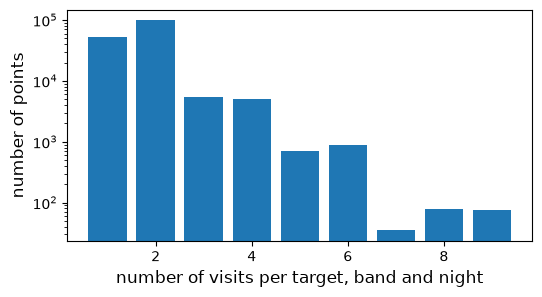

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(coadded["nvisits"], bins=np.arange(0.5, coadded["nvisits"].max() + 1.5), rwidth=0.8)
ax.set_xlabel("number of visits per target, band and night", fontsize="large")
ax.set_ylabel("number of points", fontsize="large")
ax.set_yscale("log");

Here is a SN Ia whose visits are mostly below the 5 sigma detection threshold, but whose co-added points are
detected: the one gaining the most detections.

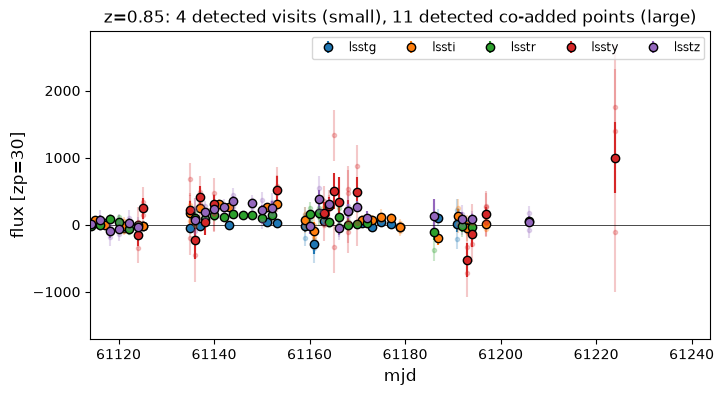

In [6]:
def get_snr(data):
    """signal-to-noise ratio of each point"""
    return data["flux"] / data["fluxerr"]

ndet_visits = (get_snr(dset.data) >= 5).groupby(level=0).sum()
ndet_coadded = (get_snr(coadded) >= 5).groupby(level=0).sum()
index = (ndet_coadded - ndet_visits.reindex(ndet_coadded.index, fill_value=0)).idxmax()
target = snia.data.loc[index]

visits_, coadded_ = dset.data.loc[index], coadded.loc[index]
fig, ax = plt.subplots(figsize=(8, 4))
for i, band_ in enumerate(sorted(coadded_["band"].unique())):
    vis_ = visits_[visits_["band"] == band_]
    co_ = coadded_[coadded_["band"] == band_]
    ax.errorbar(vis_["mjd"], vis_["flux"], vis_["fluxerr"], ls="none", marker=".", color=f"C{i}", alpha=0.25)
    ax.errorbar(co_["mjd"], co_["flux"], co_["fluxerr"], ls="none", marker="o", mec="k", color=f"C{i}", label=band_)

ax.axhline(0, color="k", lw=0.5)
ax.set_xlim(target["t0"] - 20 * (1 + target["z"]), target["t0"] + 50 * (1 + target["z"]))
ax.set_xlabel("mjd", fontsize="large")
ax.set_ylabel(f"flux [zp={coadded_['zp'].iloc[0]:.0f}]", fontsize="large")
ax.set_title(f"z={target['z']:.2f}: {ndet_visits.get(index, 0)} detected visits (small), "
             f"{ndet_coadded[index]} detected co-added points (large)")
ax.legend(ncol=6, fontsize="small");

And here is a typical SN Ia (the median number of detected co-added points), with
{meth}`~skysurvey.DataSet.show_target_lightcurve`: the visits alone (left), and the same visits faded with the
co-added points on top (right). The lines show the true model.

The colors of the bands in the plots are defined in `skysurvey.config.BAND_COLORS`; the LSST bands have none yet,
so we set them here (otherwise each band gets a color from the matplotlib cycle, which may differ between the data
points and the model).

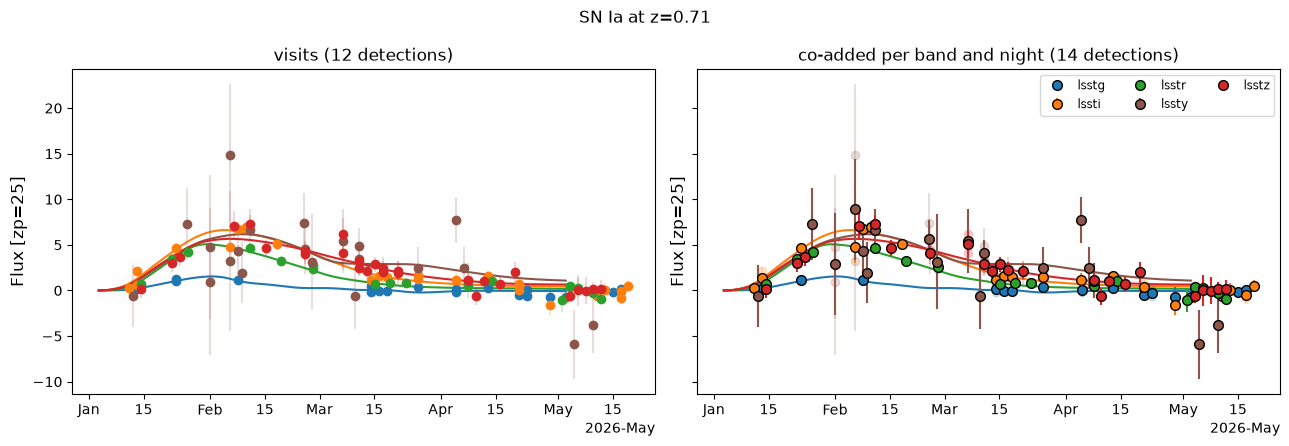

In [7]:
from astropy.time import Time
from skysurvey.config import BAND_COLORS, get_band_color

# colors of the LSST bands, from blue to red
BAND_COLORS.update({"lsstu": "tab:purple", "lsstg": "tab:blue", "lsstr": "tab:green",
                    "lssti": "tab:orange", "lsstz": "tab:red", "lssty": "tab:brown"})

detected = ndet_coadded[ndet_coadded >= 5]
typical = (detected - detected.median()).abs().idxmin()
z = snia.data.loc[typical, "z"]
phase_window = np.array([-20, 60]) * (1 + z) # observer-frame days around t0
zp = 25 # zero point of the plot

fig, (axv, axc) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
_ = dset.show_target_lightcurve(ax=axv, index=typical, zp=zp, phase_window=phase_window)
_ = dset.show_target_lightcurve(ax=axc, index=typical, zp=zp, phase_window=phase_window, alpha=0.2)

# co-added points on top, in the same zero point and time format
coadded_ = coadded.loc[typical]
t0 = snia.data.loc[typical, "t0"]
coadded_ = coadded_[coadded_["mjd"].between(*(t0 + phase_window))]
coef = 10**(-0.4 * (coadded_["zp"] - zp))
for band_ in coadded_["band"].unique():
    flag = coadded_["band"] == band_
    axc.errorbar(Time(coadded_.loc[flag, "mjd"], format="mjd").datetime,
                 coadded_.loc[flag, "flux"] * coef[flag], coadded_.loc[flag, "fluxerr"] * coef[flag],
                 ls="none", marker="o", ms=7, mec="k", mew=1, color=get_band_color(band_),
                 ecolor=get_band_color(band_), elinewidth=1.5, zorder=10, label=band_)

axv.set_title(f"visits ({ndet_visits.get(typical, 0)} detections)")
axc.set_title(f"co-added per band and night ({ndet_coadded[typical]} detections)")
axc.legend(ncol=3, fontsize="small")
fig.suptitle(f"SN Ia at z={z:.2f}")
fig.tight_layout()

## Is the co-addition right?

The co-added fluxes must be consistent with the true ones within their errors: their pulls,
(co-added - true) / error, must follow a normal distribution $\mathcal{N}(0, 1)$.

pulls: mean +0.001, std 1.001


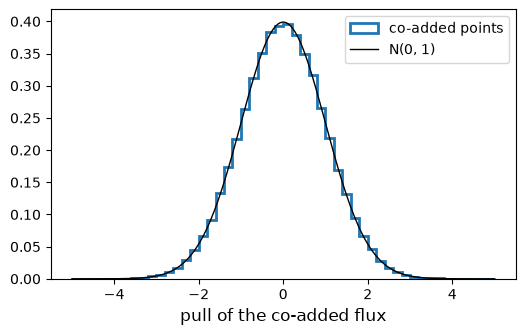

In [8]:
coadded_true = truth.get_data(join_bandday=True, join_how="coadd")
pull = (coadded["flux"] - coadded_true["flux"]) / coadded["fluxerr"]
print(f"pulls: mean {pull.mean():+.3f}, std {pull.std():.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(pull, bins=np.linspace(-5, 5, 51), density=True, histtype="step", lw=2, label="co-added points")
xx = np.linspace(-5, 5, 200)
ax.plot(xx, np.exp(-0.5 * xx**2) / np.sqrt(2 * np.pi), color="k", lw=1, label="N(0, 1)")
ax.set_xlabel("pull of the co-added flux", fontsize="large")
ax.legend();

## What it changes for detections

{meth}`~skysurvey.DataSet.get_ndetection` counts the points with flux/fluxerr $\geq 5$ (here between $-10$ and
$+40$ rest-frame days). Per visit, several visits of the same night count several times; with `join_how="first"` or
`"last"`, a single visit per night is kept (and the others are lost); with `join_how="coadd"`, all the visits of
the night contribute to a single, deeper point.

In [9]:
phase_range = [-10, 40]
ndetections = {"per visit": dset.get_ndetection(phase_range=phase_range)}
for join_how in ["first", "last", "coadd"]:
    ndetections[f'join_how="{join_how}"'] = dset.get_ndetection(phase_range=phase_range, join_bandday=True,
                                                                join_how=join_how)

pandas.DataFrame({name_: {"detected SNe Ia": len(ndet_), "detections": ndet_.sum()}
                  for name_, ndet_ in ndetections.items()}).T

,detected SNe Ia,detections
per visit,684,13011
"join_how=""first""",656,7731
"join_how=""last""",648,7697
"join_how=""coadd""",746,9933


Per visit, the number of detections is the largest, but it counts the same night several times. Co-added,
each night counts once, and more SNe Ia are detected: the gain is at high redshift, where the SNe Ia are faint.

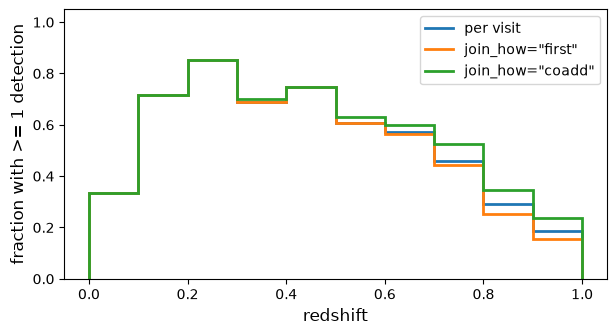

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
zbins = np.linspace(0, 1, 11)
ndrawn = np.histogram(snia.data["z"], zbins)[0]
for name_ in ["per visit", 'join_how="first"', 'join_how="coadd"']:
    detected = ndetections[name_].index
    ax.stairs(np.histogram(snia.data.loc[detected, "z"], zbins)[0] / np.maximum(ndrawn, 1), zbins, lw=2, label=name_)

ax.set_xlabel("redshift", fontsize="large")
ax.set_ylabel("fraction with >= 1 detection", fontsize="large")
ax.set_ylim(0, 1.05)
ax.legend();

## Co-add over several nights

For the faintest transients, one night may not be enough: `join_bandday` also accepts a number of nights, e.g.
`join_bandday=3` co-adds the observations of each band over 3 nights (`True` is 1 night). The windows are
consecutive blocks of N nights starting at the first night of the survey logs, the same for all targets; the `night`
column is the first night of the window, and `mjd` the weighted mean time of the co-added visits.

The flux of a transient changes over the window: co-adding over N nights averages it. This is fine to count
detections, but keep N short with respect to the timescale of the transient (N observer-frame days are N/(1+z)
rest-frame days).

In [11]:
ndetections_nights = {}
for nnights in [1, 2, 3, 5]:
    ndetections_nights[nnights] = dset.get_ndetection(phase_range=phase_range, join_bandday=nnights)

pandas.DataFrame({f"join_bandday={n_}": {"detected SNe Ia": len(ndet_), "detections": ndet_.sum()}
                  for n_, ndet_ in ndetections_nights.items()}).T

,detected SNe Ia,detections
join_bandday=1,746,9933
join_bandday=2,746,9920
join_bandday=3,771,8841
join_bandday=5,787,7730


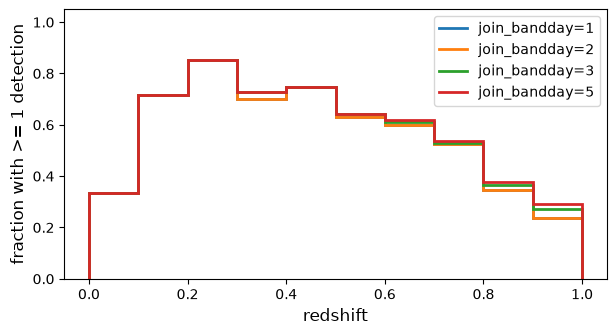

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for nnights, ndet_ in ndetections_nights.items():
    ax.stairs(np.histogram(snia.data.loc[ndet_.index, "z"], zbins)[0] / np.maximum(ndrawn, 1), zbins, lw=2,
              label=f"join_bandday={nnights}")

ax.set_xlabel("redshift", fontsize="large")
ax.set_ylabel("fraction with >= 1 detection", fontsize="large")
ax.set_ylim(0, 1.05)
ax.legend();

Longer windows detect a few more of the faint, high-redshift SNe Ia (here +5% with 5 nights, mostly at
$z > 0.8$), with fewer but deeper points per lightcurve. Joining 2 nights changes little: the visits of a band in
this deep field are rarely on consecutive nights. Here is a high-redshift SN Ia co-added per night (left) and over 3
nights (right), with `show_target_lightcurve(coadd=3)`:

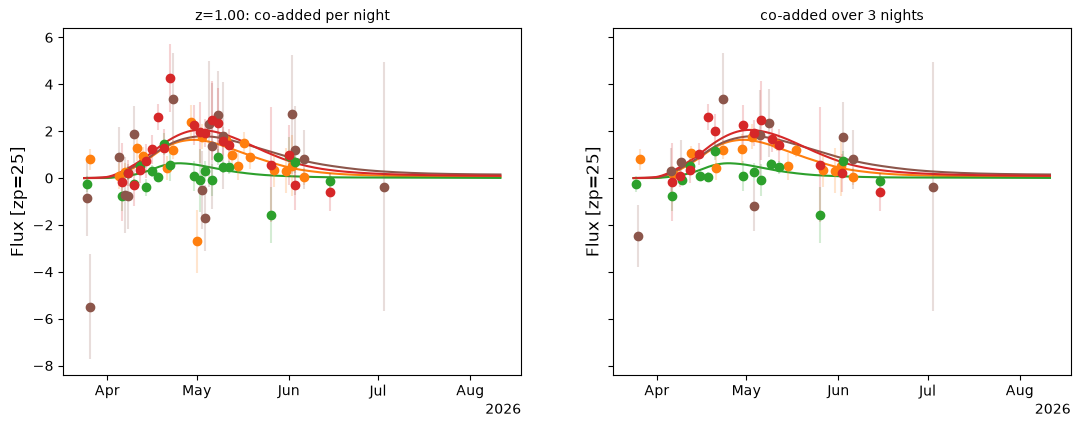

In [13]:
highz = snia.data.loc[ndetections_nights[3].index, "z"].idxmax()
phase_window = np.array([-20, 60]) * (1 + snia.data.loc[highz, "z"])

fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
_ = dset.show_target_lightcurve(ax=ax1, index=highz, zp=zp, phase_window=phase_window, coadd=True)
_ = dset.show_target_lightcurve(ax=ax3, index=highz, zp=zp, phase_window=phase_window, coadd=3)
ax1.set_title(f"z={snia.data.loc[highz, 'z']:.2f}: co-added per night", fontsize="medium")
ax3.set_title("co-added over 3 nights", fontsize="medium");

## Summary

- `dset.get_ndetection(join_bandday=True)` co-adds the observations of each band and night (`join_how="coadd"`, the
  default), with the nights defined from the survey logs.
- `dset.get_data(join_bandday=True, join_how="coadd")` gives the co-added points themselves (`night`, `nvisits`).
- `join_how="first"` or `"last"` keep a single observation per band and night.
- `join_bandday=N` (an integer) joins over windows of N nights instead of one, e.g. `get_ndetection(join_bandday=3)`
  or `show_target_lightcurve(coadd=3)`.
- The night boundary can be set with `boundary=` (fraction of the UT day), e.g. from
  `survey.get_night_boundary(longitude=...)` for a space telescope.